Gerekli kütüphanelerin importu


In [19]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import gradio as gr
import time
import os
import random

# GPU kontrolü
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("Kullanılan cihaz:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU bulunamadı. CPU kullanılacak.")


PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130
Kullanılan cihaz: cuda
GPU: Tesla T4


Oxford-IIIT Pet veri setini indirme

Veri seti indiriliyor, lütfen bekleyin...

Veri seti başarıyla indirildi!
Eğitim + doğrulama görüntü sayısı: 3680
Test görüntü sayısı: 3669


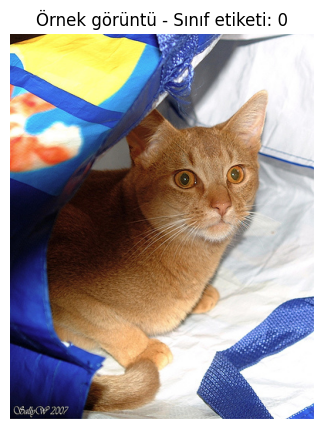

In [20]:

# Oxford-IIIT Pet veri setini indirme

from torchvision.datasets import OxfordIIITPet

print("Veri seti indiriliyor, lütfen bekleyin...")

trainval_dataset = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True
)

test_dataset = OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    download=True
)

print("\nVeri seti başarıyla indirildi!")
print("Eğitim + doğrulama görüntü sayısı:", len(trainval_dataset))
print("Test görüntü sayısı:", len(test_dataset))

# Örnek görüntüyü inceleme
image, label = trainval_dataset[0]

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"Örnek görüntü - Sınıf etiketi: {label}")
plt.axis("off")
plt.show()


#### Veri setini inceleyelim  
Burada önemli bir ayrıntı var: Oxford-IIIT Pet veri seti yalnızca iki sınıftan oluşmuyor. İçerisinde 37 farklı kedi ve köpek ırkı var. Biz bunları iki ana sınıfa dönüştüreceğiz.

Önce veri setimizden farklı fotoğrafları inceleyelim.

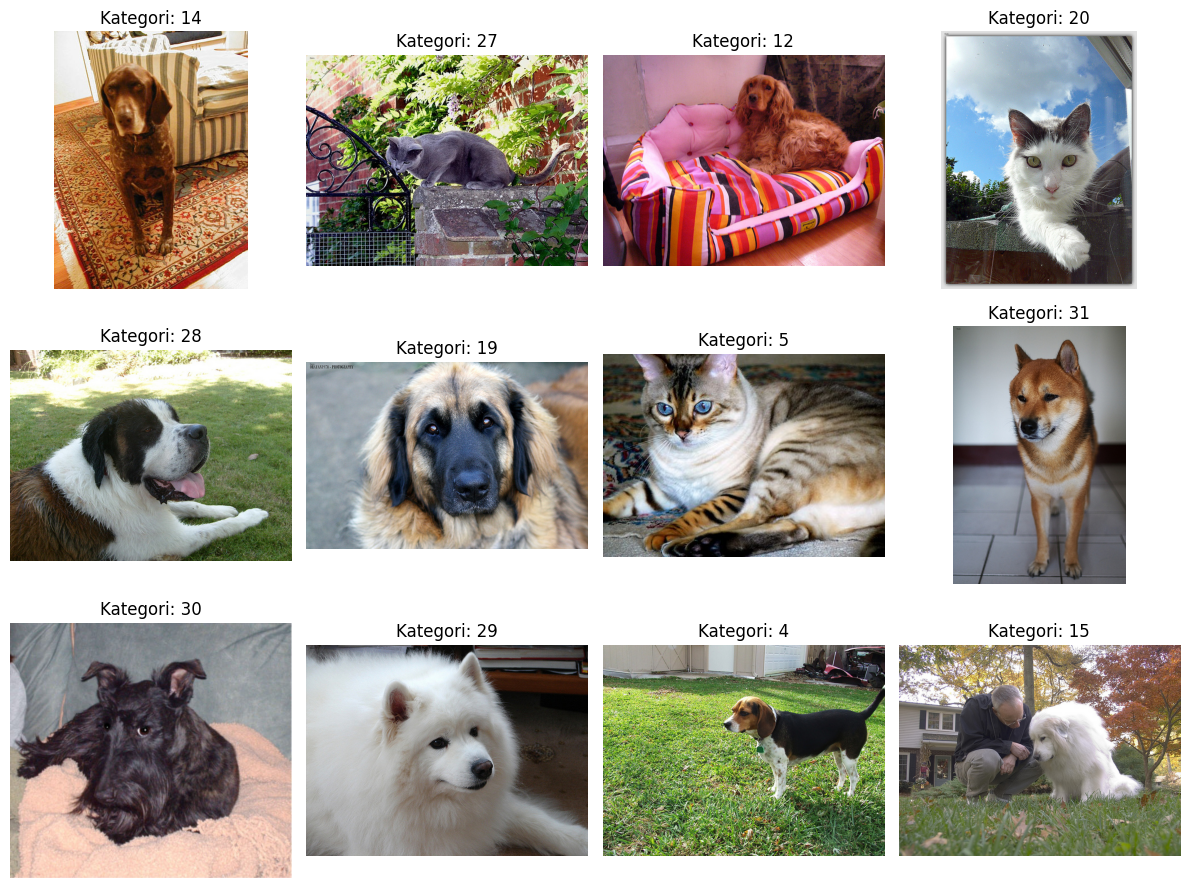

In [21]:
# Rastgele 12 fotoğraf seç
indices = random.sample(range(len(trainval_dataset)), 12)

plt.figure(figsize=(12, 9))

for i, idx in enumerate(indices):
    image, label = trainval_dataset[idx]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(f"Kategori: {label}")
    plt.axis("off")

plt.tight_layout()
plt.show()


### Verileri ayırma


In [22]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np

# Kategori etiketlerini al
labels = np.array(trainval_dataset._labels)

# Eğitim ve doğrulama indekslerini oluştur
train_indices, val_indices = train_test_split(
    np.arange(len(trainval_dataset)),
    test_size=0.15,
    random_state=42,
    stratify=labels
)

# Veri kümelerini oluştur
train_data = Subset(trainval_dataset, train_indices)
val_data = Subset(trainval_dataset, val_indices)
test_data = test_dataset

print("VERİ SETİ AYRIMI TAMAMLANDI")
print("--------------------------------")
print("Eğitim görüntüleri:", len(train_data))
print("Doğrulama görüntüleri:", len(val_data))
print("Test görüntüleri:", len(test_data))
print("--------------------------------")

print("Kedi etiketi (1):", np.sum(labels == 1))
print("Köpek etiketi (2):", np.sum(labels == 2))


VERİ SETİ AYRIMI TAMAMLANDI
--------------------------------
Eğitim görüntüleri: 3128
Doğrulama görüntüleri: 552
Test görüntüleri: 3669
--------------------------------
Kedi etiketi (1): 100
Köpek etiketi (2): 100


Küçük bir etiket ayrıntısı var: Oxford-IIIT Pet veri setinde 37 farklı ırk bulunuyor. labels == 1 ve labels == 2 kontrolleri bütün kedileri ve köpekleri saymıyor; yalnızca ilk iki ırkın sayısını gösteriyor. Dolayısıyla ekrandaki 100 ve 100 değerleri toplam kedi/köpek sayıları değil.

Bunu şimdi doğru şekilde belirleyelim. Böylece modelimiz ırkları değil, gerçekten kedi ve köpek ayrımını öğrenecek.

##### Kedi ve köpek etiketlerini kontrol etme

In [23]:

from collections import Counter

print("Veri setindeki sınıflar:")
print("--------------------------------")

print("Toplam farklı etiket:", len(set(trainval_dataset._labels)))
print("Etiket değerleri:", sorted(set(trainval_dataset._labels)))

print("\nIrk isimleri:")
print("--------------------------------")

print(trainval_dataset.classes)

print("\nEtiket dağılımı:")
print("--------------------------------")

print(Counter(trainval_dataset._labels))


Veri setindeki sınıflar:
--------------------------------
Toplam farklı etiket: 37
Etiket değerleri: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]

Irk isimleri:
--------------------------------
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']

Etiket dağılımı:
--------------------------------
Counter({0: 100, 1: 100, 2: 100, 3: 100, 4: 100, 5: 100, 6: 100, 8: 100, 9: 100,

##### Etiketleri dönüştürme
Bir önemli düzeltme daha: Eğitim ve doğrulama verilerimizi az önce orijinal ırk etiketlerine göre ayırmıştık. Şimdi etiketleri ikili sınıfa dönüştüreceğiz. Test verilerinin etiketlerini de aynı şekilde dönüştüreceğiz.

In [24]:

from torch.utils.data import Dataset
from collections import Counter

# Kedi ırkları
cat_breeds = [
    'Abyssinian',
    'Bengal',
    'Birman',
    'Bombay',
    'British Shorthair',
    'Egyptian Mau',
    'Maine Coon',
    'Persian',
    'Ragdoll',
    'Russian Blue',
    'Siamese',
    'Sphynx'
]

# Kedi ırklarının etiket numaralarını bul
cat_indices = {
    i for i, name in enumerate(trainval_dataset.classes)
    if name in cat_breeds
}

# Etiketleri Cat=0, Dog=1 olarak dönüştür
class BinaryPetDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]

        binary_label = 0 if label in cat_indices else 1

        return image, binary_label


# Yeni veri kümelerini oluştur
train_binary = BinaryPetDataset(train_data)
val_binary = BinaryPetDataset(val_data)
test_binary = BinaryPetDataset(test_dataset)

# Sınıf dağılımlarını hesapla
def show_distribution(dataset, name):
    counts = Counter(
        dataset[i][1] for i in range(len(dataset))
    )

    print(f"\n{name}")
    print("Kedi:", counts[0])
    print("Köpek:", counts[1])
    print("Toplam:", len(dataset))


print("İKİLİ SINIFLANDIRMA TAMAMLANDI")
print("0 = Kedi | 1 = Köpek")

show_distribution(train_binary, "Eğitim")
show_distribution(val_binary, "Doğrulama")
show_distribution(test_binary, "Test")


İKİLİ SINIFLANDIRMA TAMAMLANDI
0 = Kedi | 1 = Köpek

Eğitim
Kedi: 1010
Köpek: 2118
Toplam: 3128

Doğrulama
Kedi: 178
Köpek: 374
Toplam: 552

Test
Kedi: 1183
Köpek: 2486
Toplam: 3669


Artık modelimiz 37 farklı hayvan ırkı yerine sadece iki sınıf öğrenecek:
- 0 = Kedi
- 1 = Köpek  


Bir gözlemimiz var: Köpek fotoğrafları kedi fotoğraflarından daha fazla. Bu nedenle eğitim sırasında sınıf dengesizliğini dikkate alacağız. Modelin sürekli köpek tahmini yaparak yanıltıcı derecede yüksek accuracy elde etmesini istemiyoruz.

###Görüntüleri modele hazırlama
Bilgisayarımız fotoğrafları doğrudan insan gibi algılamaz. Bu yüzden bütün fotoğrafları aynı boyuta getirip sayısal tensörlere dönüştüreceğiz.

Kullanacağımız ayarlar:  
(  
Görüntü boyutu:	         128 × 128,  
Renk kanalı:	             RGB,  
Batch size:	             32,  
Veri tipi:	               Tensor,  
Normalizasyon:	           0.5    
)


##### Görüntü dönüşümleri ve DataLoader

In [25]:

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Görüntü dönüşümleri
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

# Görüntüleri ve ikili etiketleri hazırlama
class PreparedPetDataset(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]

        if self.transform:
            image = self.transform(image)

        return image, label


# Eğitim, doğrulama ve test kümeleri
train_prepared = PreparedPetDataset(train_binary, transform)
val_prepared = PreparedPetDataset(val_binary, transform)
test_prepared = PreparedPetDataset(test_binary, transform)

# DataLoader oluşturma
train_loader = DataLoader(
    train_prepared,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_prepared,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_prepared,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoader işlemi tamamlandı!")
print("Eğitim batch sayısı:", len(train_loader))
print("Doğrulama batch sayısı:", len(val_loader))
print("Test batch sayısı:", len(test_loader))


DataLoader işlemi tamamlandı!
Eğitim batch sayısı: 98
Doğrulama batch sayısı: 18
Test batch sayısı: 115


##### Modelimize gidecek veriyi kontrol edelim

In [26]:

# Bir batch veri al
images, labels = next(iter(train_loader))

print("Görüntü boyutu:", images.shape)
print("Etiket boyutu:", labels.shape)
print("Etiket örnekleri:", labels[:10].tolist())
print("Veri tipi:", images.dtype)
print("GPU:", device)

# GPU üzerinde test
images = images.to(device)
labels = labels.to(device)

print("GPU'ya aktarıldı:", images.device)
print("GPU üzerindeki etiketler:", labels.device)

print("Benzersiz etiketler:", torch.unique(labels).tolist())


Görüntü boyutu: torch.Size([32, 3, 128, 128])
Etiket boyutu: torch.Size([32])
Etiket örnekleri: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Veri tipi: torch.float32
GPU: cuda
GPU'ya aktarıldı: cuda:0
GPU üzerindeki etiketler: cuda:0
Benzersiz etiketler: [0, 1]


### CNN modelimizi oluşturalım
Kendi CNN (Convolutional Neural Network) mimarimizi oluşturacağız.

Modelimizin yapısı:
1. Convolution katmanı: Görüntü özelliklerini çıkarır.
2. ReLU: Aktivasyon uygular.
3. MaxPooling: Görüntü boyutunu küçültür.
4. Birden fazla CNN katmanı: Daha karmaşık özellikleri öğrenir.
5. Fully Connected: Sınıflandırma yapar.
6. Çıkış: Kedi veya köpek.

#### CNN model kodu

In [27]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# CNN Modeli
class CatDogCNN(nn.Module):
    def __init__(self):
        super(CatDogCNN, self).__init__()

        # 1. Evrişim katmanı
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # 2. Evrişim katmanı
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # 3. Evrişim katmanı
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        # Tam bağlantılı katmanlar
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


# Modeli oluştur ve GPU'ya gönder
model = CatDogCNN().to(device)

print(model)
print("\nModel başarıyla oluşturuldu!")
print("Model cihazı:", next(model.parameters()).device)

# Parametre sayısı
total_params = sum(p.numel() for p in model.parameters())
print("Toplam parametre sayısı:", total_params)


CatDogCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=2, bias=True)
)

Model başarıyla oluşturuldu!
Model cihazı: cuda:0
Toplam parametre sayısı: 618754


#### Modelimizi test edelim

In [28]:

# Örnek görüntüleri GPU'ya gönder
images, labels = next(iter(train_loader))
images = images.to(device)

# Modeli değerlendirme moduna al
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Giriş boyutu:", images.shape)
print("Model çıkış boyutu:", outputs.shape)
print("Beklenen çıkış: [32, 2]")

assert outputs.shape == (32, 2)

print("\nCNN MODELİ TESTİ BAŞARILI!")


Giriş boyutu: torch.Size([32, 3, 128, 128])
Model çıkış boyutu: torch.Size([32, 2])
Beklenen çıkış: [32, 2]

CNN MODELİ TESTİ BAŞARILI!


### Modeli eğitimi


#### Eğitim ayarları
| Parametre | Değer |
| --- | --- |
| Model | CatDogCNN |
| Input Size | 128 × 128 |
| Batch Size | 32 |
| Epoch | 15 |
| Optimizer | Adam |
| Learning Rate | 0.001 |
| Loss Function | Weighted CrossEntropyLoss |
| Aktivasyon | ReLU |
| Dropout | 0.5 |
| GPU | Tesla T4 |


#### Optimizer ve Loss Function

In [29]:

import torch.optim as optim

# Sınıf ağırlıklarını hesapla
class_counts = torch.tensor([1010, 2118], dtype=torch.float32)

class_weights = class_counts.sum() / (2 * class_counts)
class_weights = class_weights.to(device)

# Loss Function
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Epoch sayısı
num_epochs = 15

print("Eğitim ayarları hazır!")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Loss Function: Weighted CrossEntropyLoss")
print("Epoch:", num_epochs)
print("Class Weights:", class_weights)


Eğitim ayarları hazır!
Optimizer: Adam
Learning Rate: 0.001
Loss Function: Weighted CrossEntropyLoss
Epoch: 15
Class Weights: tensor([1.5485, 0.7384], device='cuda:0')


#### Modeli eğitme
Şimdi en önemli aşamaya geldik. Modelimiz fotoğraflardan öğrenmeye başlayacak.

Aşağıdaki kod eğitim ve doğrulama işlemlerini yapacak. En iyi doğrulama başarısına sahip modeli best_catdog_model.pth adıyla kaydedecek.


In [30]:

import time
import copy

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

start_time = time.time()

for epoch in range(num_epochs):

    # EĞİTİM
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = 100 * correct / total

    # DOĞRULAMA
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    # En iyi modeli kaydet
    if epoch_val_acc > best_val_accuracy:

        best_val_accuracy = epoch_val_acc
        best_model_weights = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_weights,
            "best_catdog_model.pth"
        )

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Acc: {epoch_train_acc:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )

total_training_time = time.time() - start_time

# En iyi ağırlıkları geri yükle
model.load_state_dict(best_model_weights)

print("\nEĞİTİM TAMAMLANDI!")
print("En iyi doğrulama başarısı:", best_val_accuracy)
print("Toplam eğitim süresi:", round(total_training_time, 2), "saniye")


Epoch [1/15] Train Loss: 0.7046 Train Acc: 57.96% Val Loss: 0.6329 Val Acc: 59.60%
Epoch [2/15] Train Loss: 0.6473 Train Acc: 63.27% Val Loss: 0.6245 Val Acc: 68.30%
Epoch [3/15] Train Loss: 0.6153 Train Acc: 66.18% Val Loss: 0.6018 Val Acc: 69.75%
Epoch [4/15] Train Loss: 0.5976 Train Acc: 67.68% Val Loss: 0.5913 Val Acc: 70.47%
Epoch [5/15] Train Loss: 0.5823 Train Acc: 68.80% Val Loss: 0.5767 Val Acc: 65.94%
Epoch [6/15] Train Loss: 0.5630 Train Acc: 71.61% Val Loss: 0.5671 Val Acc: 70.47%
Epoch [7/15] Train Loss: 0.5455 Train Acc: 72.19% Val Loss: 0.5464 Val Acc: 72.46%
Epoch [8/15] Train Loss: 0.5388 Train Acc: 72.31% Val Loss: 0.5482 Val Acc: 72.46%
Epoch [9/15] Train Loss: 0.5022 Train Acc: 76.60% Val Loss: 0.5186 Val Acc: 76.81%
Epoch [10/15] Train Loss: 0.4832 Train Acc: 76.57% Val Loss: 0.5396 Val Acc: 72.83%
Epoch [11/15] Train Loss: 0.4702 Train Acc: 77.69% Val Loss: 0.5400 Val Acc: 75.91%
Epoch [12/15] Train Loss: 0.4715 Train Acc: 78.74% Val Loss: 0.5217 Val Acc: 75.36%
E

#### Eğitim sonuçları

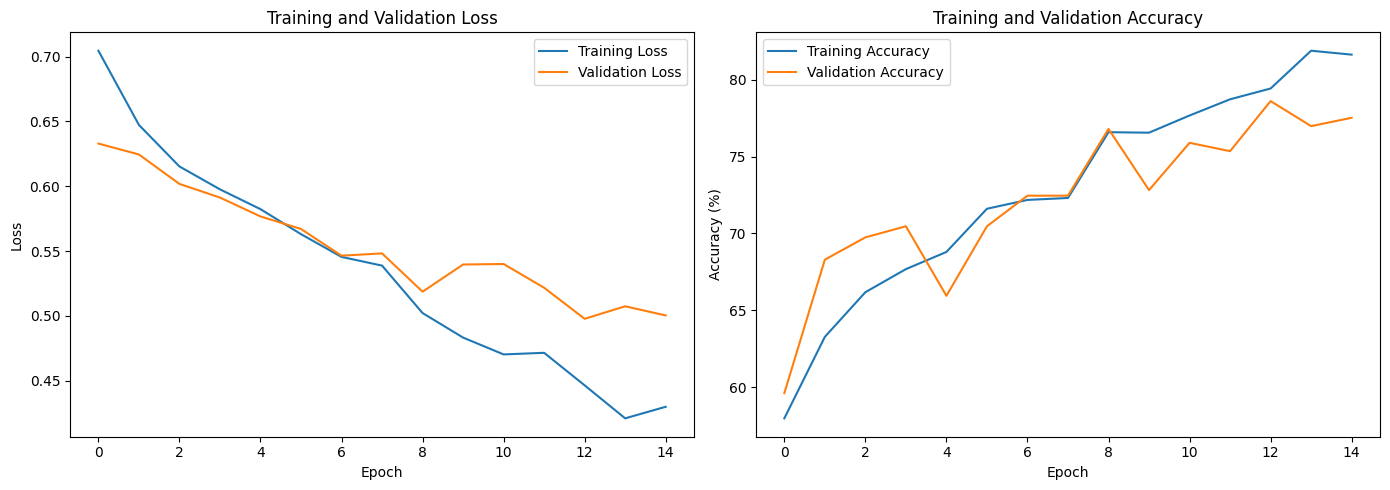

In [31]:

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()


### Test verisi üzerinde değerlendirme


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import numpy as np
import torch

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Metrikleri hesapla
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="binary")
recall = recall_score(all_labels, all_predictions, average="binary")
f1 = f1_score(all_labels, all_predictions, average="binary")

print("TEST SONUÇLARI")
print("------------------------")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

print("\nSINIFLANDIRMA RAPORU")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Cat", "Dog"]
))

print("CONFUSION MATRIX")
print(confusion_matrix(all_labels, all_predictions))

TEST SONUÇLARI
------------------------
Accuracy : 80.49%
Precision: 86.91%
Recall   : 83.83%
F1 Score : 85.34%

SINIFLANDIRMA RAPORU
              precision    recall  f1-score   support

         Cat       0.68      0.73      0.71      1183
         Dog       0.87      0.84      0.85      2486

    accuracy                           0.80      3669
   macro avg       0.78      0.79      0.78      3669
weighted avg       0.81      0.80      0.81      3669

CONFUSION MATRIX
[[ 869  314]
 [ 402 2084]]


### Test sonuçlarının yorumu

| Metrik | Sonuç |
| --- | --- |
| Accuracy | %80.49 |
| Precision (Dog) | %86.91 |
| Recall (Dog) | %83.83 |
| F1-Score (Dog) | %85.34 |
| Cat F1-Score | %71 |
| Dog F1-Score | %85 |

**Confusion Matrix:**

| Gerçek / Tahmin | Cat | Dog |
| --- | ---: | ---: |
| Cat | 869 | 314 |
| Dog | 402 | 2084 |


- 1.183 kedi görselinin 869'u doğru, 314'ü yanlış sınıflandırılmıştır.
- 2.486 köpek görselinin 2.084'ü doğru, 402'si yanlış sınıflandırılmıştır.

Önemli gözlem: Model köpekleri kedilere kıyasla daha başarılı tanımaktadır. Bunun olası nedenlerinden biri veri setinde köpek görsellerinin daha fazla olmasıdır. Sınıf ağırlıkları kullanılmasına rağmen iki sınıf arasındaki başarı farkı devam etmektedir.


#### Inference Time (Tahmin Süresi)

In [33]:

import time
import torch

model.eval()

total_images = 0
total_time = 0

# GPU'nun ilk çalıştırma gecikmesini ölçüme katmamak için
warmup_images, _ = next(iter(test_loader))
warmup_images = warmup_images.to(device)

with torch.no_grad():
    for _ in range(5):
        _ = model(warmup_images)

if device.type == "cuda":
    torch.cuda.synchronize()

# Test veri setinde tahmin süresini ölç
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        outputs = model(images)

        if device.type == "cuda":
            torch.cuda.synchronize()

        end_time = time.perf_counter()

        total_time += end_time - start_time
        total_images += images.size(0)

average_time = total_time / total_images
average_time_ms = average_time * 1000

print("INFERENCE TIME RESULTS")
print("----------------------")
print(f"Total images: {total_images}")
print(f"Total inference time: {total_time:.4f} seconds")
print(f"Average inference time per image: {average_time_ms:.4f} ms")


INFERENCE TIME RESULTS
----------------------
Total images: 3669
Total inference time: 0.9914 seconds
Average inference time per image: 0.2702 ms


### Uygulama – Gradio

Gradio kurulumu

In [34]:
!pip install gradio

Gradio uygulamasını oluşturma

In [35]:
import gradio as gr
import torch
from PIL import Image

# Modeli değerlendirme moduna al
model.eval()

class_names = ["Cat", "Dog"]

def predict_image(image):
    # Görüntüyü RGB formatına dönüştür
    image = image.convert("RGB")

    # Eğitimde kullandığımız dönüşümleri uygula
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Tahmin yap
    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    # Sınıf olasılıklarını döndür
    return {
        class_names[0]: float(probabilities[0]),
        class_names[1]: float(probabilities[1])
    }

# Gradio arayüzü
demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil", label="Bir kedi veya köpek fotoğrafı yükleyin"),
    outputs=gr.Label(num_top_classes=2, label="Model Tahmini"),
    title="Cat vs Dog Image Classifier",
    description="Yüklediğiniz görselin kedi mi köpek mi olduğunu yapay zekâ modeliyle tahmin eder."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e978c70df694ee040c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Gerçek Görüntülerle Test ve Değerlendirme.

Saving dog2.jpeg to dog2 (1).jpeg
Saving dog1.jpeg to dog1 (1).jpeg
Saving cat3.jpeg to cat3 (1).jpeg
Saving cat2.jpeg to cat2 (1).jpeg
Saving cat1.jpeg to cat1 (1).jpeg


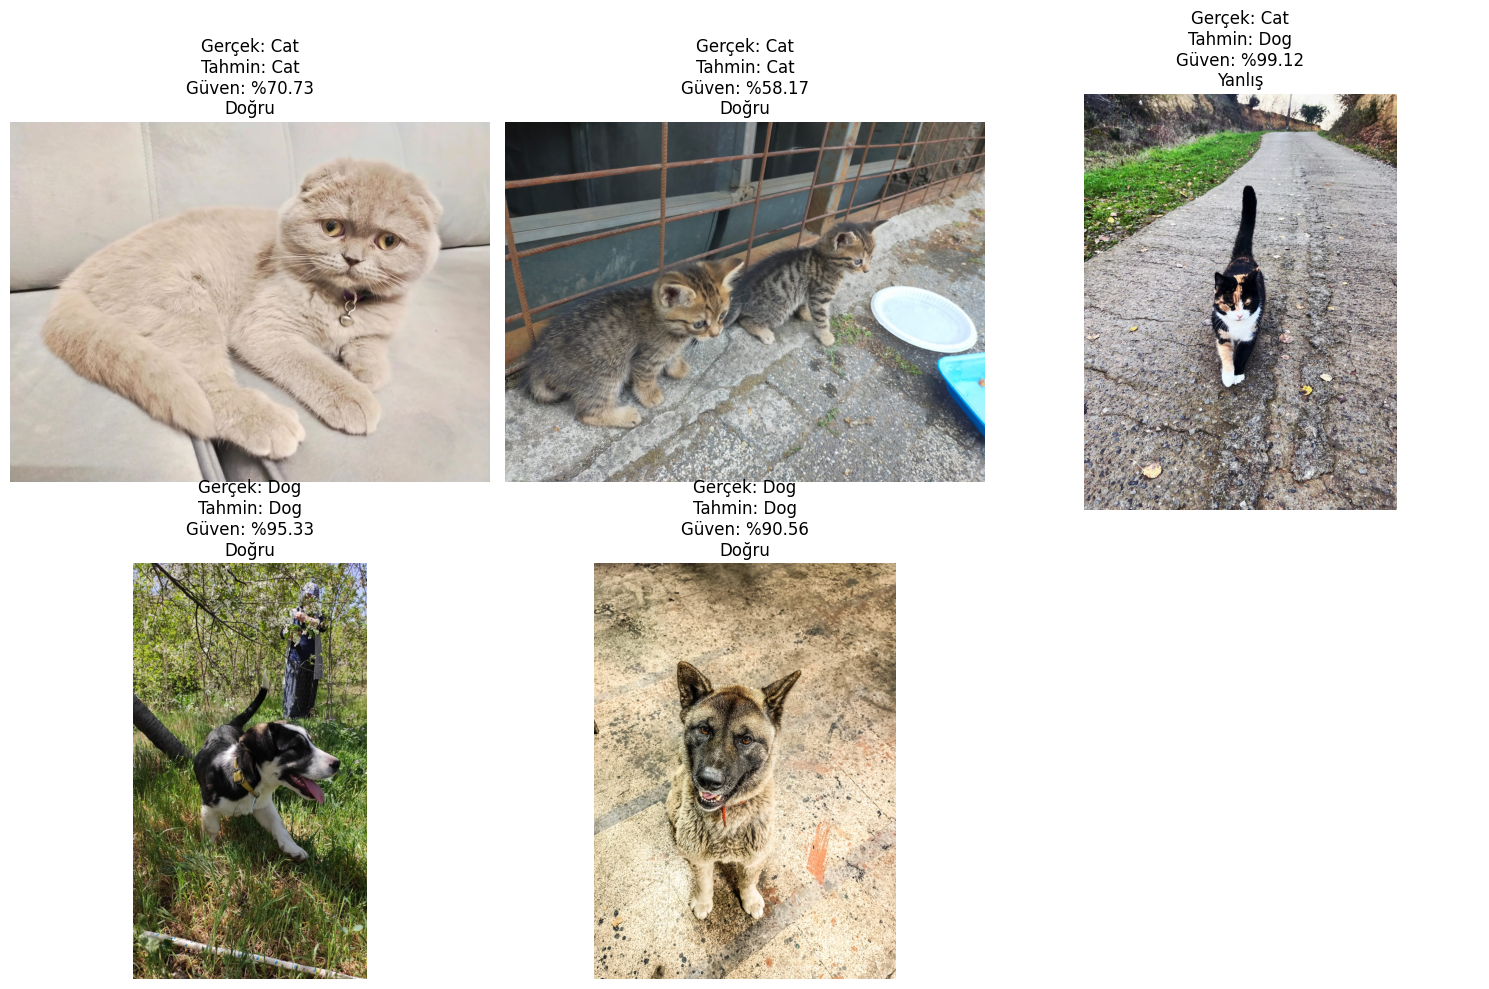

,Fotoğraf,Gerçek Sınıf,Model Tahmini,Güven (%),Sonuç
0,cat1 (1).jpeg,Cat,Cat,70.73,Doğru
1,cat2 (1).jpeg,Cat,Cat,58.17,Doğru
2,cat3 (1).jpeg,Cat,Dog,99.12,Yanlış
3,dog1 (1).jpeg,Dog,Dog,95.33,Doğru
4,dog2 (1).jpeg,Dog,Dog,90.56,Doğru


Toplam fotoğraf: 5
Doğru tahmin: 4
Yanlış tahmin: 1
Başarı oranı: %80.00


In [36]:

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch
import os

# Bilgisayardan 5 fotoğrafı yükle
uploaded = files.upload()

# Dosya isimlerine göre gerçek sınıfları belirle
image_files = sorted(uploaded.keys())

class_names = ["Cat", "Dog"]

# Modeli değerlendirme moduna al
model.eval()

# Sonuçları sakla
results = []

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, filename in enumerate(image_files):
    # Fotoğrafı aç
    image = Image.open(filename).convert("RGB")

    # Dosya adından gerçek sınıfı belirle
    if filename.lower().startswith("cat"):
        actual_class = 0
    elif filename.lower().startswith("dog"):
        actual_class = 1
    else:
        raise ValueError(f"Dosya adı cat veya dog ile başlamalı: {filename}")

    # Görüntüyü modele hazırla
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Tahmin yap
    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.softmax(output, dim=1)[0]
        prediction = torch.argmax(probabilities).item()

    confidence = probabilities[prediction].item() * 100
    correct = prediction == actual_class

    results.append({
        "Fotoğraf": filename,
        "Gerçek Sınıf": class_names[actual_class],
        "Model Tahmini": class_names[prediction],
        "Güven (%)": round(confidence, 2),
        "Sonuç": "Doğru" if correct else "Yanlış"
    })

    # Fotoğrafı ve tahminini göster
    axes[i].imshow(image)
    axes[i].set_title(
        f"Gerçek: {class_names[actual_class]}\n"
        f"Tahmin: {class_names[prediction]}\n"
        f"Güven: %{confidence:.2f}\n"
        f"{'Doğru' if correct else 'Yanlış'}"
    )
    axes[i].axis("off")

# Kullanılmayan son grafiği kapat
for j in range(len(image_files), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# Sonuç tablosu
import pandas as pd

results_df = pd.DataFrame(results)
display(results_df)

correct_count = sum(r["Sonuç"] == "Doğru" for r in results)

print(f"Toplam fotoğraf: {len(results)}")
print(f"Doğru tahmin: {correct_count}")
print(f"Yanlış tahmin: {len(results) - correct_count}")
print(f"Başarı oranı: %{correct_count / len(results) * 100:.2f}")


#### Gerçek görüntülerle test sonuçları  
| | Fotoğraf | Gerçek Sınıf | Model Tahmini | Güven (%) | Sonuç |
| --- | --- | --- | --- | --- | --- |
| 0 | cat1 (1).jpeg | Cat | Cat | 70.73 | Doğru |
| 1 | cat2 (1).jpeg | Cat | Cat | 58.17 | Doğru |
| 2 | cat3 (1).jpeg | Cat | Dog | 99.12 | Yanlış |
| 3 | dog1 (1).jpeg | Dog | Dog | 95.33 | Doğru |
| 4 | dog2 (1).jpeg | Dog | Dog | 90.56 | Doğru |

Başarılı tahminler:
- Model iki farklı kedi fotoğrafını doğru sınıflandırdı.
- İki farklı köpek fotoğrafını da doğru tahmin etti.
- Farklı ortam, ışık ve arka planlarda çalışabildiğini gösterdi.  

Başarısız tahmin:
- Üçüncü kedi fotoğrafını %99.12 güvenle köpek olarak sınıflandırdı.
- Bu sonuç, modelin her zaman doğru tahmin yapmadığını ve yüksek güven yüzdesinin doğruluk garantisi olmadığını gösteriyor.
- Fotoğraftaki kedinin uzaktan ve görece küçük görünmesi, arka plan ve görüntü özellikleri bu hataya katkıda bulunmuş olabilir. Ancak bunun kesin nedenini yalnızca bu testten belirleyemeyiz.

#### Değerlendirme
Eğitilen CNN modeli, gerçek yaşam koşullarındaki performansını değerlendirmek amacıyla beş farklı kedi ve köpek fotoğrafı üzerinde test edilmiştir. Fotoğraflar Gradio arayüzü ve Google Colab notebook'u aracılığıyla modele girdi olarak verilmiştir.

Test sonucunda model, beş fotoğrafın dördünü doğru sınıflandırmış ve %80 başarı oranı elde etmiştir. İki kedi ve iki köpek fotoğrafı doğru tahmin edilirken, bir kedi fotoğrafı köpek olarak sınıflandırılmıştır.

Özellikle üçüncü fotoğrafta modelin %99.12 güvenle yanlış tahmin yapması dikkat çekicidir. Bu durum, modelin bazı görüntülerde sınıflandırma hataları yapabildiğini ve yüksek güven değerinin her zaman doğru tahmin anlamına gelmediğini göstermektedir.

Genel olarak model, test edilen gerçek görüntülerin çoğunda başarılı sonuç vermiştir. Bununla birlikte, test fotoğrafı sayısının sınırlı olması nedeniyle bu sonuçlar modelin tüm gerçek yaşam koşullarındaki başarısını temsil etmemektedir.